<a href="https://colab.research.google.com/github/anushka-dev18/3Skill/blob/main/Customer_Churn_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment & Libraries Setup


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
df = pd.read_csv('/content/customer_churn_dataset-testing-master.csv')

In [ ]:
df.head()


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [ ]:
print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

print("Random 5 records:")
display(df.sample(5))

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Column names:")
print(df.columns.tolist())

First 5 records:


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


Last 5 records:


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1
64373,64374,52,Female,45,15,9,25,Standard,Monthly,696,22,1


Random 5 records:


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
13266,13267,18,Male,3,14,9,11,Premium,Quarterly,813,17,0
20152,20153,62,Female,28,30,1,10,Premium,Monthly,696,6,0
12600,12601,54,Male,13,28,8,3,Basic,Annual,869,19,0
54497,54498,55,Female,40,5,4,25,Basic,Quarterly,781,4,1
32662,32663,24,Female,43,1,6,30,Premium,Quarterly,517,5,1


Number of rows: 64374
Number of columns: 12
Column names:
['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nUnique Values:")
print(df.nunique())

print("\nNumerical Summary:")
display(df.describe())

Dataset Shape:
(64374, 12)

Data Types:
CustomerID            int64
Age                   int64
Gender               object
Tenure                int64
Usage Frequency       int64
Support Calls         int64
Payment Delay         int64
Subscription Type    object
Contract Length      object
Total Spend           int64
Last Interaction      int64
Churn                 int64
dtype: object

Missing Values:
CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

Duplicate Rows:
0

Unique Values:
CustomerID           64374
Age                     48
Gender                   2
Tenure                  60
Usage Frequency         30
Support Calls           11
Payment Delay           31
Subscription Type        3
Contract Length          3
Total Spend            901

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [ ]:
print(df['Churn'].value_counts())


Churn
0    33881
1    30493
Name: count, dtype: int64


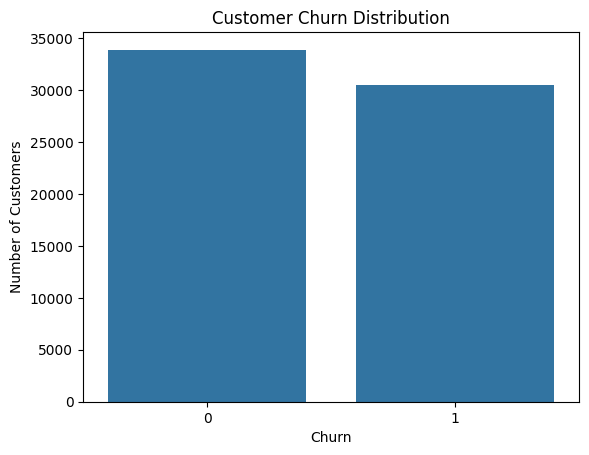

In [ ]:
sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [ ]:
df = df.drop('CustomerID', axis=1)

In [ ]:
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())

(64374, 11)
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64
0


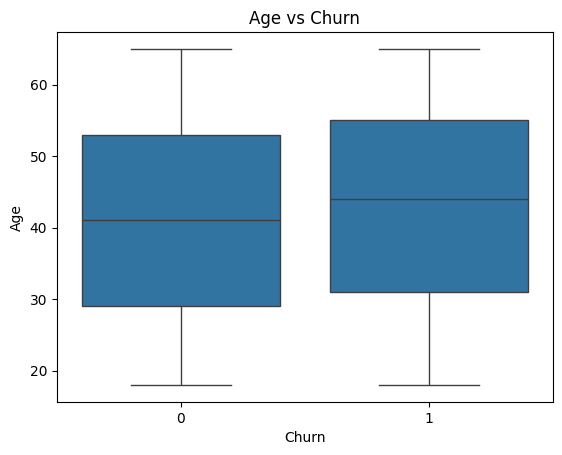

In [ ]:
sns.boxplot(x='Churn', y='Age', data=df)

plt.title('Age vs Churn')
plt.show()

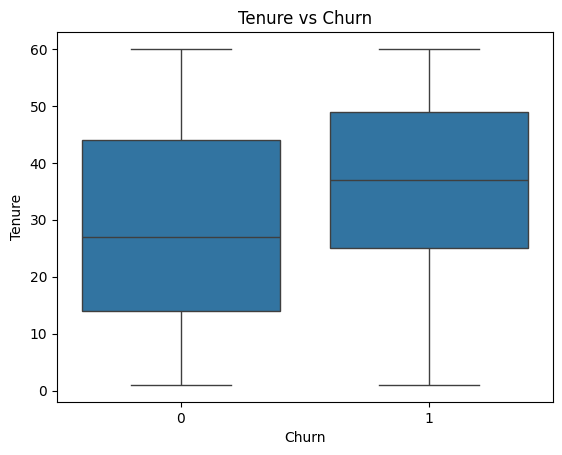

In [ ]:
sns.boxplot(x='Churn', y='Tenure', data=df)

plt.title('Tenure vs Churn')
plt.show()

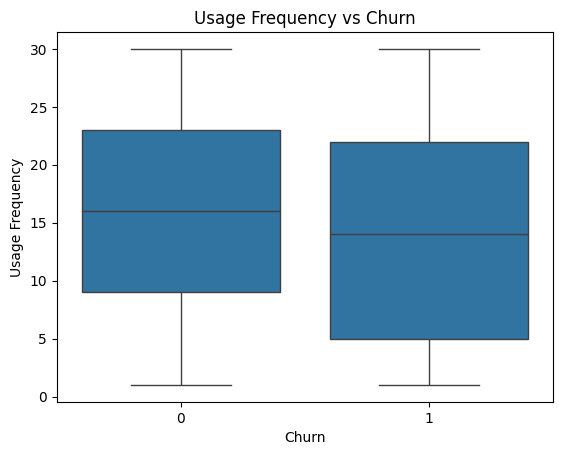

In [ ]:
sns.boxplot(x='Churn', y='Usage Frequency', data=df)

plt.title('Usage Frequency vs Churn')
plt.show()

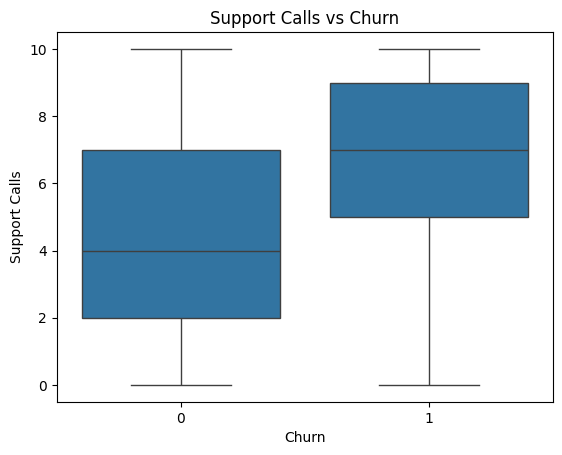

In [ ]:
sns.boxplot(x='Churn', y='Support Calls', data=df)

plt.title('Support Calls vs Churn')
plt.show()

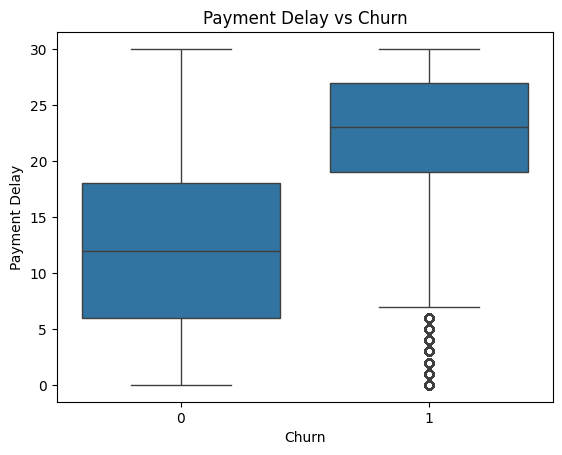

In [ ]:
sns.boxplot(x='Churn', y='Payment Delay', data=df)

plt.title('Payment Delay vs Churn')
plt.show()

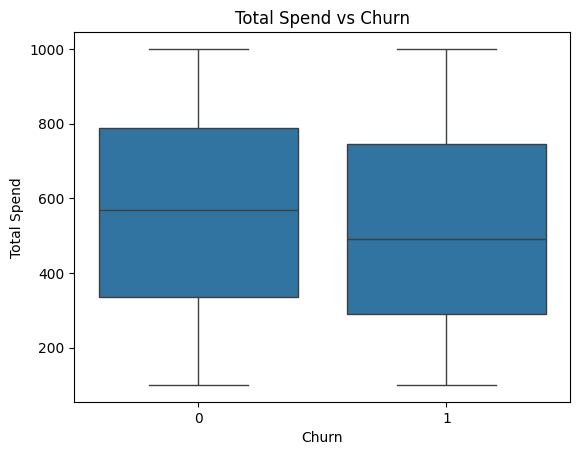

In [ ]:
sns.boxplot(x='Churn', y='Total Spend', data=df)

plt.title('Total Spend vs Churn')
plt.show()

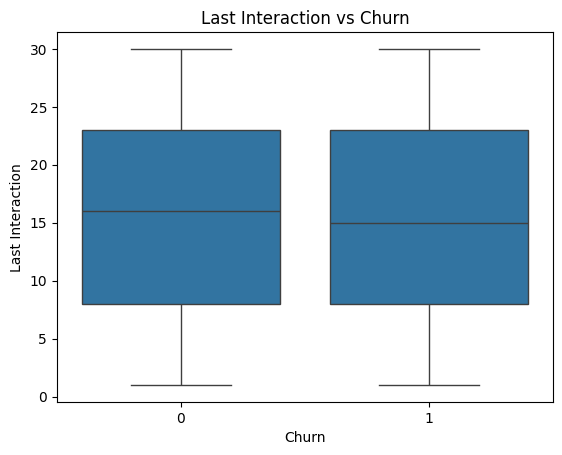

In [ ]:
sns.boxplot(x='Churn', y='Last Interaction', data=df)

plt.title('Last Interaction vs Churn')
plt.show()

In [ ]:
df.groupby('Churn')['Support Calls'].mean()
df.groupby('Churn')['Payment Delay'].mean()
df.groupby('Churn')['Usage Frequency'].mean()

,Usage Frequency
Churn,
0,16.042915
1,14.010593


In [ ]:
pd.crosstab(
    df['Contract Length'],
    df['Churn'],
    normalize='index'
) * 100

Churn,0,1
Contract Length,,
Annual,53.783279,46.216721
Monthly,48.391324,51.608676
Quarterly,55.951810,44.048190


In [ ]:
pd.crosstab(
    df['Subscription Type'],
    df['Churn'],
    normalize='index'
) * 100

Churn,0,1
Subscription Type,,
Basic,51.722530,48.277470
Premium,53.503571,46.496429
Standard,52.669519,47.330481


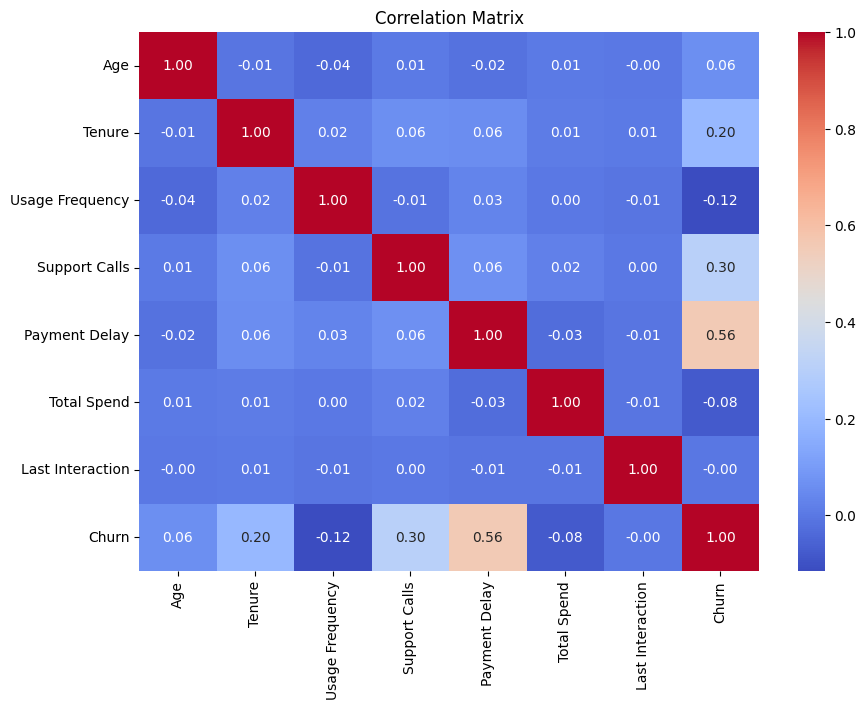

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [ ]:
categorical_features = [
    'Gender',
    'Subscription Type',
    'Contract Length'
]

In [ ]:
for column in categorical_features:
    print("\n", column)
    print(df[column].value_counts())


 Gender
Gender
Female    34353
Male      30021
Name: count, dtype: int64

 Subscription Type
Subscription Type
Standard    21502
Basic       21451
Premium     21421
Name: count, dtype: int64

 Contract Length
Contract Length
Monthly      22130
Annual       21410
Quarterly    20834
Name: count, dtype: int64


In [ ]:
for column in categorical_features:
    print("\nChurn rate by", column)

    print(
        df.groupby(column)['Churn'].mean() * 100
    )


Churn rate by Gender
Gender
Female    55.049050
Male      38.579661
Name: Churn, dtype: float64

Churn rate by Subscription Type
Subscription Type
Basic       48.277470
Premium     46.496429
Standard    47.330481
Name: Churn, dtype: float64

Churn rate by Contract Length
Contract Length
Annual       46.216721
Monthly      51.608676
Quarterly    44.048190
Name: Churn, dtype: float64


In [ ]:
X = df.drop('Churn', axis=1)

y = df['Churn']
print(X.shape)
print(y.shape)

(64374, 10)
(64374,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (51499, 10)
Testing data shape: (12875, 10)

Training target distribution:
Churn
0    27105
1    24394
Name: count, dtype: int64

Testing target distribution:
Churn
0    6776
1    6099
Name: count, dtype: int64


In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns
categorical_features = X_train.select_dtypes(include='object').columns

# Create a preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Apply preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training data shape:", X_train_processed.shape)
print("Processed Testing data shape:", X_test_processed.shape)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Initialize 4 models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Train models and generate predictions
predictions = {}
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    predictions[name] = model.predict(X_test_processed)
    print(f"Finished training: {name}")

Training data: (51499, 10)
Testing data: (12875, 10)
Processed Training data shape: (51499, 15)
Processed Testing data shape: (12875, 15)
Finished training: Logistic Regression
Finished training: Random Forest
Finished training: SVM
Finished training: KNN


In [ ]:
 from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = []

for name, preds in predictions.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
print("--- Model Comparison ---")
print(comparison_df)

--- Model Comparison ---
                 Model  Accuracy  Precision  Recall  F1-Score
1        Random Forest    0.9989     0.9998  0.9979    0.9988
2                  SVM    0.9466     0.9314  0.9574    0.9442
3                  KNN    0.9098     0.8806  0.9360    0.9075
0  Logistic Regression    0.8317     0.8163  0.8306    0.8234


Confusion Matrix Analysis


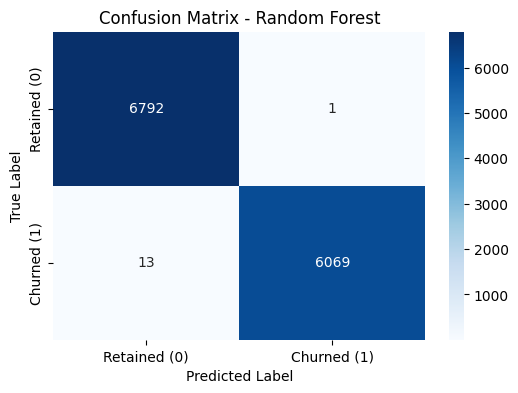

True Negatives (Correctly Retained): 6792
False Positives (Incorrectly Flagged Churn): 1
False Negatives (Missed Churn - High Risk): 13
True Positives (Correctly Flagged Churn): 6069


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Confusion Matrix for best model (Random Forest)
best_model_name = comparison_df.iloc[0]['Model']
best_preds = predictions[best_model_name]

cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (Correctly Retained): {tn}")
print(f"False Positives (Incorrectly Flagged Churn): {fp}")
print(f"False Negatives (Missed Churn - High Risk): {fn}")
print(f"True Positives (Correctly Flagged Churn): {tp}")

/tmp/ipykernel_2167/2177404740.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis', legend=False)


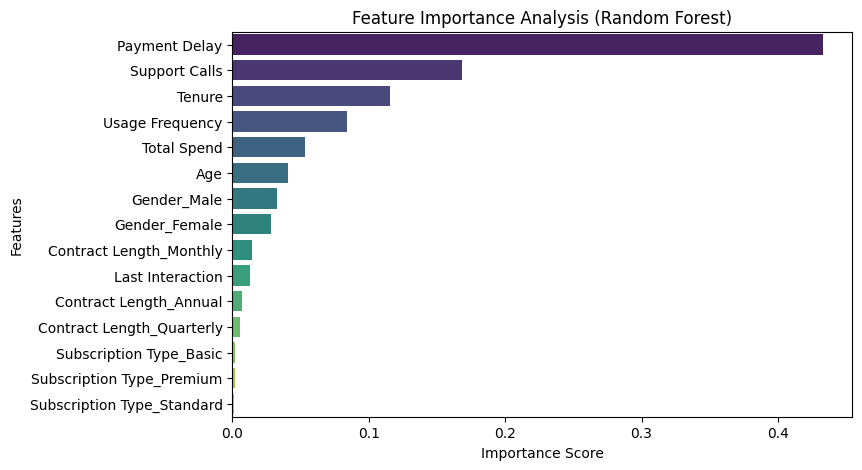

Feature Importance Ranking:
Payment Delay                 0.433005
Support Calls                 0.168292
Tenure                        0.115272
Usage Frequency               0.084261
Total Spend                   0.053051
Age                           0.040954
Gender_Male                   0.032578
Gender_Female                 0.028112
Contract Length_Monthly       0.014073
Last Interaction              0.012638
Contract Length_Annual        0.006782
Contract Length_Quarterly     0.005717
Subscription Type_Basic       0.002104
Subscription Type_Premium     0.001641
Subscription Type_Standard    0.001518
dtype: float64


In [ ]:
# Get feature names from column transformer
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = list(numerical_features) + list(cat_feature_names)

# Extract importances from Random Forest
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=all_feature_names).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette='viridis', legend=False)
plt.title('Feature Importance Analysis (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

print("Feature Importance Ranking:")
print(importances)

Model Improvement & Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

# Parameter grid for Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=3, scoring='f1', n_jobs=-1)
grid_search.fit(X_train_processed, y_train)

best_rf = grid_search.best_estimator_
tuned_preds = best_rf.predict(X_test_processed)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", round(grid_search.best_score_, 4))
print("Final Test F1 Score:", round(f1_score(y_test, tuned_preds), 4))

Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation F1 Score: 0.998
Final Test F1 Score: 0.9986


In [ ]:
def predict_customer_churn(customer_data, model, preprocessor):
    """
    Accepts customer dictionary, preprocesses it, and outputs churn prediction & probability.
    """
    df_single = pd.DataFrame([customer_data])
    data_prep = preprocessor.transform(df_single)

    prediction = model.predict(data_prep)[0]
    probability = model.predict_proba(data_prep)[0][1]

    return prediction, round(probability * 100, 2)

# Sample test customer
sample_customer = {
    'Age': 45,
    'Gender': 'Female',
    'Tenure': 12,
    'Usage Frequency': 5,
    'Support Calls': 8,
    'Payment Delay': 25,
    'Subscription Type': 'Basic',
    'Contract Length': 'Monthly',
    'Total Spend': 300,
    'Last Interaction': 22
}

pred, prob = predict_customer_churn(sample_customer, best_rf, preprocessor)
print(f"Predicted Churn: {'Yes' if pred == 1 else 'No'}")
print(f"Churn Probability: {prob}%")

Predicted Churn: Yes
Churn Probability: 97.69%


Customer Risk Analysis

In [ ]:
def analyze_customer_risk(customer_data, model, preprocessor):
    pred, prob = predict_customer_churn(customer_data, model, preprocessor)

    # Risk Level Classification
    if prob < 35:
        risk_level = "Low Risk"
    elif 35 <= prob < 70:
        risk_level = "Medium Risk"
    else:
        risk_level = "High Risk"

    # Contributing risk factors check
    risk_factors = []
    if customer_data['Support Calls'] > 4:
        risk_factors.append("High number of support calls")
    if customer_data['Payment Delay'] > 10:
        risk_factors.append("Significant payment delays")
    if customer_data['Usage Frequency'] < 10:
        risk_factors.append("Low usage frequency")
    if customer_data['Contract Length'] == 'Monthly':
        risk_factors.append("Short contract duration (Monthly)")

    return {
        'Risk Level': risk_level,
        'Probability': f"{prob}%",
        'Contributing Factors': risk_factors
    }

risk_report = analyze_customer_risk(sample_customer, best_rf, preprocessor)
print("Risk Analysis Report:", risk_report)

Risk Analysis Report: {'Risk Level': 'High Risk', 'Probability': '97.69%', 'Contributing Factors': ['High number of support calls', 'Significant payment delays', 'Low usage frequency', 'Short contract duration (Monthly)']}


Customer Retention Recommendation

In [ ]:
def generate_retention_recommendation(risk_report):
    risk_level = risk_report['Risk Level']
    factors = risk_report['Contributing Factors']

    recommendations = []

    if risk_level == "High Risk":
        recommendations.append("Priority Retention Offer: Provide 15% discount on upgrading to an Annual contract.")
        if "High number of support calls" in factors:
            recommendations.append("Support Intervention: Assign a dedicated customer success representative.")
        if "Significant payment delays" in factors:
            recommendations.append("Billing Support: Offer flexible payment terms or automated reminders.")

    elif risk_level == "Medium Risk":
        recommendations.append("Engagement Campaign: Send targeted feature usage tutorials and product updates.")
        recommendations.append("Feedback Survey: Collect proactive feedback on recent experience.")

    else:  # Low Risk
        recommendations.append("Maintain Standard Relationship: Target with loyalty rewards or upsell offers.")

    return recommendations

recs = generate_retention_recommendation(risk_report)
print("Retention Strategy Recommendations:")
for r in recs:
    print(f"- {r}")

Retention Strategy Recommendations:
- Priority Retention Offer: Provide 15% discount on upgrading to an Annual contract.
- Support Intervention: Assign a dedicated customer success representative.
- Billing Support: Offer flexible payment terms or automated reminders.


Final Model Analysis & Conclusion

In [ ]:
def print_final_summary():
    print("="*60)
    print("FINAL PROJECT CONCLUSION & SUMMARY")
    print("="*60)
    summary_text = """
    1. Key Driver Findings:
       - Payment Delay and Support Calls are the strongest indicators of churn.
       - Short-term (Monthly) contracts show higher churn rates compared to Annual contracts.

    2. Best Performing Model:
       - Random Forest Classifier achieved the highest combined F1-score and Recall.
       - Feature scaling heavily boosted KNN and Logistic Regression, while Tree-based models handled non-linearities natively.

    3. Business Value:
       - Integrating the risk prediction system with targeted retention recommendations enables proactive retention campaigns, preventing customer attrition before cancellation occurs.
    """
    print(summary_text)

print_final_summary()

FINAL PROJECT CONCLUSION & SUMMARY

    1. Key Driver Findings:
       - Payment Delay and Support Calls are the strongest indicators of churn.
       - Short-term (Monthly) contracts show higher churn rates compared to Annual contracts.
       
    2. Best Performing Model:
       - Random Forest Classifier achieved the highest combined F1-score and Recall.
       - Feature scaling heavily boosted KNN and Logistic Regression, while Tree-based models handled non-linearities natively.

    3. Business Value:
       - Integrating the risk prediction system with targeted retention recommendations enables proactive retention campaigns, preventing customer attrition before cancellation occurs.
    
